# Shared conventions for students

Make sure that independent simulation runs use fresh random draws. Include the actual numerical parameters, algorithm, and step size in the report. Where two models are compared, use matched initial configurations adapted to their respective state spaces.

For a graph with adjacency matrix $A_{ij}$ the degree of vertex $i$ is $d_i = \sum_j A_{ij}$. The *empirical mean* is the average over agents

$$
m(t) = \frac{1}{N}\sum_{i=1}^N X_i(t),
$$

and a common disagreement measure is

$$
V(t) = \frac{1}{N}\sum_{i=1}^N |X_i(t) - m(t)|^2,
$$

where $|\cdot|$ denotes absolute value for scalar states and Euclidean norm for vectors.

# Project 2: Small-World Shortcuts and Epidemic Spreading

## Central question

Does adding long-range contacts to a local contact network change how often a finite epidemic develops into a large outbreak?

## Models

Consider a continuous-time *SIS Markov jump process* on an undirected contact network $A$. An infected vertex $I = 1$ recovers at rate $\gamma$; a susceptible vertex $I = 0$ is infected at rate $\beta$ times the number of infected neighbours:

$$
I_i : 0 \to 1 \text{ at rate } \beta \sum_j A_{ij} I_j, \qquad I_i : 1 \to 0 \text{ at rate } \gamma.
$$

The state is $I \in \{0,1\}^N$; the all-susceptible state is absorbing.

## Project requirements

1. **Networks.** Let $N = 40$. Construct (A) the degree-4 ring lattice and (B) a Watts–Strogatz graph obtained by rewiring ring edges with probability $p = 0.20$, e.g. `watts_strogatz_graph(40,4,0.2,seed=7)`; regenerate if disconnected. Keep the edge count unchanged. Report mean degree, clustering coefficient, and a graph drawing.
2. **Rates and generator.** Derive infection and recovery rates. For the total number of infected $F(I) = \sum_i I_i$, show that $(\mathcal{L}F)(I)$ is the sum of infection rates minus the sum of recovery rates. Explain why configurations with the same infected count can have different expected instantaneous changes.
3. **Initial state and parameters.** Start with only vertices 0 and 1 infected on each graph. Set $\gamma = 1$ and compare $\beta = 0.25$ and $0.50$. Run until $T = 20$ or until infection extinction.
4. **Gillespie experiment.** For each of the four graph/$\beta$ conditions, simulate 40 independent trajectories. Record the infected count $F(I(t))$, peak infected fraction $\max_{t \le T} F(I(t))/N$, and whether the count reaches 10 by $T$. Record extinction times where observed; do not call $T$ an extinction time for surviving trajectories.
5. **Comparison and robustness.** Estimate the fraction of runs reaching 10 infections and compare peak-infection distributions. Generate one additional small-world graph using another seed, with epidemic parameters unchanged, to assess graph-to-graph variability.

## Final discussion

Explain what the numerical results show about shortcuts. Distinguish trends from assertions about all small-world networks.

# Implementation

#### Imports

In [ ]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt


seed = 64563
# One generator for the whole notebook: every simulation run draws fresh
# random numbers from it (never re-seed inside the run loop).
rng = np.random.default_rng(seed=seed)

### Setup

#### 1. Networks

In [ ]:
# Fixed project parameters (Project 2 brief)
N = 40          # number of agents / vertices
K = 4           # ring lattice degree (2 neighbours on each side)
P_REWIRE = 0.20 # Watts–Strogatz rewiring probability
# T_MAX = 20.0    # final time
# N_RUNS = 40     # Gillespie trajectories per graph/beta condition
# THRESHOLD = 10  # "large outbreak" marker: F(t) reaches 10
# INITIAL_INFECTED = [0, 1]

G_ring : nx.Graph = nx.circulant_graph(N, [1, 2])
G_watts_strogatz : nx.Graph = nx.watts_strogatz_graph(N, K, P_REWIRE, seed=seed)

print("G_ring properties:")
print(f" - Connected: {'✔' if nx.is_connected(G_ring) else '✘'}")
print(f" - Mean degree: {2*G_ring.number_of_edges() / G_ring.number_of_nodes()}")
print(f" - Clustering coefficient: {nx.average_clustering(G_ring)}")
print("G_watts_strogatz properties:")
print(f" - Connected: {'✔' if nx.is_connected(G_watts_strogatz) else '✘'}")
print(f" - Mean degree: {2*G_watts_strogatz.number_of_edges() / G_watts_strogatz.number_of_nodes()}")
print(f" - Clustering coefficient: {nx.average_clustering(G_watts_strogatz)}")




G_ring properties:
 - Connected: ✔
 - Mean degree: 4.0
 - Clustering coefficient: 0.5
G_watts_strogatz properties:
 - Connected: ✔
 - Mean degree: 4.0
 - Clustering coefficient: 0.3025


Drawing the graphs

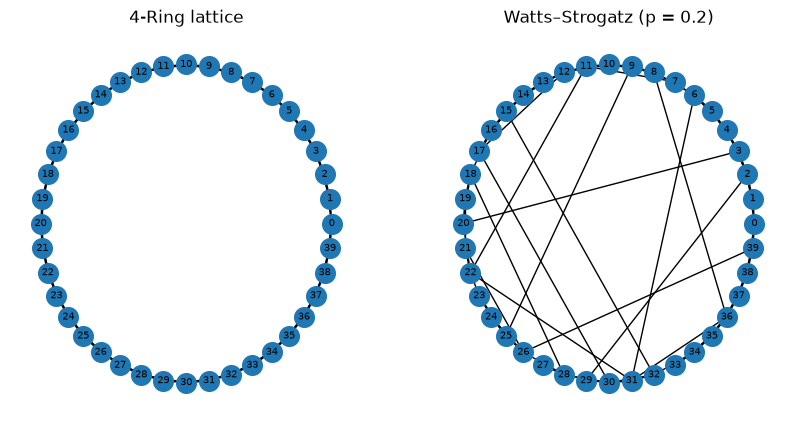

In [ ]:
fig, axes = plt.subplots(1,2,figsize=(10,5))

for ax, G, title in zip(axes, [G_ring, G_watts_strogatz], ["4-Ring lattice", f"Watts–Strogatz (p = {P_REWIRE:.2})"]):
    nx.draw(G, pos=nx.circular_layout(G), ax=ax, with_labels=True,
            node_size=200, font_size=7)
    ax.set_title(title)

plt.show()

#### 2. Rates and generator

Derive infection and recovery rates. For the total number of infected $F(I) = \sum_i I_i$, show that $(\mathcal{L}F)(I)$ is the sum of infection rates minus the sum of recovery rates. Explain why configurations with the same infected count can have different expected instantaneous changes.

In [ ]:
GAMMA = 1.0     # recovery rate
BETAS = [0.25, 0.50]  # infection rates to compare


#### 3. Initial state and parameters

#### 4. Gillespie Experiment

#### 5. Comparison and Robustness